In [95]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from statsmodels.sandbox.stats.runs import runstest_1samp
from statsmodels.stats.diagnostic import (
    acorr_breusch_godfrey,
    het_breuschpagan,
    het_white,
)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson


\newpage
\setcounter{page}{1}
## **Ejercicio 1**
Mencione y explique brevemente cuales son las principales violaciones de los supuestos de un modelo lineal clásico como se pueden detectar en la práctica.

Considerando el modelo lineal clásico:
$$\mathbf{Y}=\mathbf{X}\beta+\varepsilon\hspace{0.3cm}\text{con}\hspace{0.3cm}E(\varepsilon)=\mathbf{0}\text{,}\hspace{0.3cm}Var(\varepsilon)=\sigma^2\mathbf{I} \hspace{0.3cm}\text{y}\hspace{0.3cm}\varepsilon \sim N(\mathbf{0},\sigma^2\mathbf{I})$$
Las principales violaciones a los supuestos son:

1. **No linealidad.**

El modelo supone que la relación entre la variable respuesta y los predictores puede representarse mediante una combinación lineal de los parámetros. Así una de las violaciones ocurre cuando existe una relación funcional curva que el modelo no captura. La evidencia de esta violación se exhibe principalmente en un patrón visual en los residuales. 

**Formas de Detección:**

- Gráfico de residuos vs valores ajustados.
- Gráfico de variable de respuesta vs cada uno de los predictores
  
En ambos casos si hay algún patrón no lineal o aleatorio hay evidencia de No Linealidad.

2. **Heterocedasticidad**
   
El supuesto establece que $Var(\varepsilon)=\sigma^2$ para todas las observaciones, es decir, la varianza es constante, sin embargo, muchos de los casos ocurre que $Var(\varepsilon_i)\neq\sigma^2$, esta es uno de los supuestos que comúnmente se pasan por alto. 

**Formas de Detección:**

- Gráfico de residuos vs valores ajustados, en caso de observar algún patrón de crecimiento o decrecimiento de la varianza hay que investigar más a fondo o proceder con pruebas de hipótesis.
- Pruebas de hipótesis: Breush-Pagan, White, Spearman y Goldfed Quandt.

3. **Autocorrelación o Falta de Independencia**
   
Se supone que los errores son no correlacionados $Cov(\varepsilon_i,\varepsilon_j)=0$ para $i\neq j$. Esto cuando se trabaja con datos reales los errores $\varepsilon_1,\varepsilon_2,\cdots,\varepsilon_n$ presentan una relación consecutiva, por lo que es natural revisar si hay presencia de autocorrelación, es decir: $Cov(\varepsilon_i,\varepsilon_{i-1})\neq0$.

Sin embargo otras herramientas permiten probar correlación en la variable dependiente, general o funcional. 

**Formas de Detección:**

- Pruebas de hipótesis: Durbin-Watson, h de Durbin  y Prueba de rachas. 

4. **No normalidad de los residuos**

Aunque el modelo y la estimación por mínimos cuadrados no exige la normalidad, para el cálculo de pruebas de hipótesis e intervalos de confianza es indispensable sobre todo en muestras pequeñas  el supuesto: $\varepsilon_i\sim N(0,\sigma^2)$

**Formas de Detección:**

- Histograma de residuos.
- Q-Q Plot y P-P Plot.
- Pruebas de bondad de ajuste: Shapiro-Wilk o Jarque-Bera


4. **Multicolinealidad**

Este supuesto es particular de la regresión múltiple. Sucede cuando 2 o más variables explicativas presentan una relación lineal fuerte. Esto dificulta separar el efecto lineal de cada predictor y una consecuencia es que aunque los estimadores no dejan de insesgados, sus varianza aumentan considerablemente.

**Formas de Detección:**

- Coeficiente de correlación simples y parciales.
- $R^2$ muy elevada y coeficientes no significativos.
- Índice de tolerancia y Factor de incremento de la varianza.
- Número de condición (con la matriz diseño normalizada).

## **Ejercicio 2**
Con la siguiente información brindada en el ejercicio, se completa la tabla que queda de la siguiente forma:


In [96]:
#Datos Brindados
R2_2 = 0.9707 #Coeficiente de determinación
obs_2 = 19 #Número de observaciones
SCE_2 = 100.2369 #Suma de cuadrados de los residuos o errores
SCT_2 = 3416.8853 #Suma de cuadrados totales
b0_2 = 5.6484 #Coef del intercepto
b1_2 = 3.5785 #Coef de X
b2_2 = 0.6536 #Coef de X2
b3_2 = -0.0552 #Coef de X3
etb0_2 = 2.9547 #Error típico de b0
etb1_2 = 1.5659 #Error típico de b1
etb2_2 = 0.2313 #Error típico de b2
etb3_2 = 0.0098 #Error típico de b3

#Calculos realizados para completar la tabla
k_2 = 3 #Número de variables independientes o predictoras
coef_cor_2 = np.sqrt(R2_2) #Coeficiente de correlación múltiple
R2_aj_2 = 1-(1-R2_2)*(obs_2-1)/(obs_2-k_2-1) #Coeficiente de determinación ajustado
ett_2 = np.sqrt(SCE_2/(obs_2-k_2-1)) #Error típico total
gle_2 = obs_2-k_2-1 #Grados de libertad de la ecuación de los residuos
glt_2 = obs_2-1 #Grados de libertad de la ecuación de la regresión
SCR_2 = SCT_2-SCE_2 #Suma de cuadrados de la regresión
MSR_2 = SCR_2/k_2 #Media del cuadrado de la regresión
MSE_2 = SCE_2/gle_2 #Media del cuadrado de los residuos
F_2 = MSR_2/MSE_2 #Estadístico F asociado a la tabla ANOVA
p_valF_2 = stats.f.sf(F_2, k_2, gle_2) #p-value de la prueba F

tb0_2 = b0_2/etb0_2 #t-value de b0
tb1_2 = b1_2/etb1_2 #t-value de b1
tb2_2 = b2_2/etb2_2 #t-value de b2
tb3_2 = b3_2/etb3_2 #t-value de b3
p_valtb0_2 = stats.t.sf(np.abs(tb0_2), gle_2)*2 #p-value de la prueba t de b0
p_valtb1_2 = stats.t.sf(np.abs(tb1_2), gle_2)*2 #p-value de la prueba t de b1
p_valtb2_2 = stats.t.sf(np.abs(tb2_2), gle_2)*2 #p-value de la prueba t de b2
p_valtb3_2 = stats.t.sf(np.abs(tb3_2), gle_2)*2 #p-value de la prueba t de b3
t_975_2 = stats.t.ppf(0.975, gle_2) #Valor t de 97.5%
infb0_2 = b0_2-t_975_2*etb0_2 #Intervalo inferior de b0
supb0_2 = b0_2+t_975_2*etb0_2 #Intervalo superior de b0
infb1_2 = b1_2-t_975_2*etb1_2 #Intervalo inferior de b1
supb1_2 = b1_2+t_975_2*etb1_2 #Intervalo superior de b1
infb2_2 = b2_2-t_975_2*etb2_2 #Intervalo inferior de b2
supb2_2 = b2_2+t_975_2*etb2_2 #Intervalo superior de b2
infb3_2 = b3_2-t_975_2*etb3_2 #Intervalo inferior de b3
supb3_2 = b3_2+t_975_2*etb3_2 #Intervalo superior de b3

In [97]:
#Generamos la tabla ajuste
tabla_ajuste_2 = pd.DataFrame({"Estadístico": [
        "Coeficiente de correlación múltiple",
        "R2",
        "R2 ajustado",
        "Error típico de la estimación",
        "Observaciones"],
    "Valor": [f"{coef_cor_2:.4f}",
        f"{R2_2:.4f}",
        f"{R2_aj_2:.4f}",
        f"{ett_2:.4f}",
        f"{obs_2:d}"]})

tabla_ajuste_2.style.hide(axis="index").map(lambda x: "color: red", subset=pd.IndexSlice[[1], ["Valor"]])

Estadístico,Valor
Coeficiente de correlación múltiple,0.9852
R2,0.9707
R2 ajustado,0.9648
Error típico de la estimación,2.5850
Observaciones,19


In [98]:
#Formato tabla ANOVA
tabla_anova_2 = pd.DataFrame({"Fuente": ["Regresión", "Residuos", "Total"],
    "gl": [k_2, gle_2, glt_2],
    "SC": [SCR_2, SCE_2, SCT_2],
    "MC": [MSR_2, MSE_2, np.nan],
    "F": [F_2,np.nan,np.nan],
    "p-valor": [p_valF_2, np.nan,np.nan]})

tabla_anova_2.style.format({"SC": "{:.4f}",
    "MC": "{:.4f}",
    "F": "{:.4f}",
    "p-valor": "{:.4g}"}).hide(axis="index").map(lambda x: "color: red", subset=pd.IndexSlice[[1, 2], ["SC"]])

Fuente,gl,SC,MC,F,p-valor
Regresión,3,3316.6484,1105.5495,165.4405,1.025e-11
Residuos,15,100.2369,6.6825,nan,nan
Total,18,3416.8853,nan,nan,nan


In [99]:
#Tabla de coeficientes
tabla_coef_2 = pd.DataFrame({"Variable": ["Intercepto", "X", "X2", "X3"],
    "Coeficiente": [b0_2, b1_2, b2_2, b3_2],
    "Error Típico": [etb0_2, etb1_2, etb2_2, etb3_2],
    "Estadístico t": [tb0_2, tb1_2, tb2_2, tb3_2],
    "Probabilidad": [p_valtb0_2, p_valtb1_2, p_valtb2_2, p_valtb3_2],
    "Inferior 95%": [infb0_2, infb1_2, infb2_2, infb3_2],
    "Superior 95%": [supb0_2, supb1_2, supb2_2, supb3_2]})
#Formato
tabla_coef_2.style.format({
    "Coeficiente": "{:.4f}",
    "Error Típico": "{:.4f}",
    "Estadístico t": "{:.4f}",
    "Probabilidad": "{:.4g}",
    "Inferior 95%": "{:.4f}",
    "Superior 95%": "{:.4f}"
}).hide(axis="index").map(lambda x: "color: red", subset=pd.IndexSlice[list(range(4)),["Coeficiente", "Error Típico"]])

Variable,Coeficiente,Error Típico,Estadístico t,Probabilidad,Inferior 95%,Superior 95%
Intercepto,5.6484,2.9547,1.9117,0.07522,-0.6494,11.9462
X,3.5785,1.5659,2.2853,0.03727,0.2409,6.9161
X2,0.6536,0.2313,2.8258,0.01278,0.1606,1.1466
X3,-0.0552,0.0098,-5.6327,4.767e-05,-0.0761,-0.0343


Considerando estos estadísticos:

- El modelo presenta alto grado de ajuste, con $R^2=0.9707$ es decir el 97.07% de la varianza de la variable respuesta es explicada por $X,X2,X3$.
- La prueba F asociada a la tabla ANOVA es favorable, por lo que el modelo es estadísticamente significativo en conjunto.
- Los coeficientes de $X, X2, X3$ son estadísticamente significativos, es decir cada variable en presencia de las restantes aporta información al modelo.
- El intercepto no resulta significativo, por lo que no se rechaza que sea igual a cero.

## **Ejercicio 3**
En un laboratorio se generan reacciones químicas a partir de un material base. Se dispone del dataset reaccionesQuimicas.csv con las siguientes variables:

- $Y$: Cantidad de producto final obtenido.
- $X_1$: Temperatura (grados Celcius).
- $X_2$: Concentración de material base (%).
- $X_3$: Tiempo de reacción (horas).

En base a la información se ajusto el modelo:
$$Y=\beta_0+\beta_1X_1+\beta_2X_2+\beta_3X_3$$
Del cuál se obtuvo el siguiente ajuste:

In [100]:
#Ruta del archivo
path_3 = "C:/Users/Skull/Escritorio/OneDrive/Universidad/Modelos Lineales I/Guía 1/Quarto/reaccionesQuimicas.csv"
#path_3 = "C:/Users/emili/Desktop/OneDrive/Universidad/Modelos Lineales I/Guía 1/Quarto/reaccionesQuimicas.csv"
df_3 = pd.read_csv(path_3).iloc[:, 1:5]
X_reg_3 = df_3.iloc[:, 1:4] #Valores de las variables predictoras
X_reg_3 = sm.add_constant(X_reg_3)
Y_reg_3 = df_3.iloc[:,0] #Valores de la variable objetivo

reg_mod_3 = sm.OLS(Y_reg_3, X_reg_3).fit()

tabla_coef_3 = pd.DataFrame({"Variable": reg_mod_3.params.index,
    "Coeficiente": reg_mod_3.params.values,
    "Error estándar": reg_mod_3.bse.values,
    "t": reg_mod_3.tvalues.values,
    "p-valor": reg_mod_3.pvalues.values,
    "[0.025": reg_mod_3.conf_int()[0].values,
    "0.975]": reg_mod_3.conf_int()[1].values})


tabla_coef_3.style.format({"Coeficiente": "{:.4f}",
        "Error estándar": "{:.4f}",
        "t": "{:.4f}",
        "p-valor": "{:.2e}",
        "[0.025": "{:.4f}",
        "0.975]": "{:.4f}"}).hide(axis="index")

Variable,Coeficiente,Error estándar,t,p-valor,[0.025,0.975]
const,332.1110,18.6929,17.7667,1.74e-11,292.2679,371.9540
x1,-1.5460,0.0990,-15.6103,1.10e-10,-1.7570,-1.3349
x2,-1.4246,0.1476,-9.6482,7.99e-08,-1.7393,-1.1099
x3,-2.2374,0.3398,-6.5839,8.67e-06,-2.9617,-1.5130


Donde podemos observar que los coeficientes son significativos al tener p-values menores al nivel de significancia (0.05), un elemento a notar es que el error estándar del intercepto es grande, tal vez por alguna presencia de multicolinealidad con el. A través de los valores ajustados y residuos se obtuvo un $R^2 = 95.51\%$, dichos valores se muestran a continuación:

In [101]:
#| output: false
val_est_3 = reg_mod_3.fittedvalues #Valores estimados del modelo
res_3 = reg_mod_3.resid #Residuales obtenidos
#Acomodamos la información para mostrarla
tabla_res_3 = pd.DataFrame(
    [val_est_3.values, res_3.values],
    index=["Estimado", "Residuo"],
    columns=range(1, len(val_est_3) + 1))
tabla_res_3.style.format("{:.3f}")

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
Estimado,42.188,31.002,27.742,21.030,19.405,12.693,12.282,5.570,20.217,4.758,35.677,13.094,27.340,13.505,26.929,15.442,15.442,19.542,19.542
Residuo,-0.688,2.798,-0.042,0.670,0.495,2.307,-0.082,-1.270,-0.917,1.642,1.923,4.906,-1.040,-3.605,-1.929,-1.342,-0.242,-3.642,0.058


In [102]:
#| output: false
R2_3 = reg_mod_3.rsquared
print(f"El R2 del modelo es: {R2_3:.4f}") #R^2 obtenido

El R2 del modelo es: 0.9551


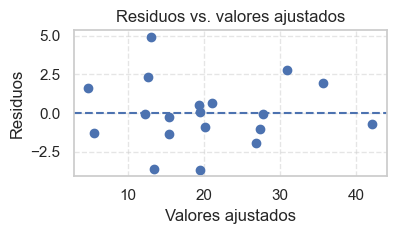

In [103]:
#| fig-align: center
plt.figure(figsize=(4, 2.5))
plt.scatter(val_est_3, res_3)
plt.axhline(0, linestyle="--")
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Residuos vs. valores ajustados")
plt.tight_layout()
plt.show()

Gráficamente, los residuos no presentan patrones o curvaturas aparentes y se distribuyen alrededor de cero con una dispersión aproximadamente constante. Esto proporciona evidencia gráfica a favor de los supuestos de linealidad y homocedasticidad. Sin embargo, la gráfica no permite evaluar por sí sola los supuestos por lo que haremos pruebas de hipótesis. Además, la tabla ANOVA del modelo propuesto nos arroja.

In [104]:
# Grados de libertad
gl_reg_3 = int(reg_mod_3.df_model)
gl_error_3 = int(reg_mod_3.df_resid)
gl_total_3 = gl_reg_3 + gl_error_3

# Sumas de cuadrados
SC_reg_3 = reg_mod_3.ess
SC_error_3 = reg_mod_3.ssr
SC_total_3 = SC_reg_3 + SC_error_3

# Cuadrados medios
CM_reg_3 = SC_reg_3 / gl_reg_3
CM_error_3 = SC_error_3 / gl_error_3

# Estadístico F y p-valor
F_3 = reg_mod_3.fvalue
p_valor_3 = reg_mod_3.f_pvalue

tabla_anova_3 = pd.DataFrame({
    "Fuente": ["Regresión", "Error", "Total"],
    "gl": [gl_reg_3, gl_error_3, gl_total_3],
    "SC": [SC_reg_3, SC_error_3, SC_total_3],
    "CM": [CM_reg_3, CM_error_3, None],
    "F": [F_3, None, None],
    "p-valor": [p_valor_3, None, None]
})


tabla_anova_3.style.format({
        "SC": "{:.4f}",
        "CM": "{:.4f}",
        "F": "{:.4f}",
        "p-valor": "{:.3e}"}).hide(axis="index")

Fuente,gl,SC,CM,F,p-valor
Regresión,3,1707.1580,569.0527,106.4664,2.459e-10
Error,15,80.1735,5.3449,nan,nan
Total,18,1787.3316,nan,nan,nan


El estadístico $F$ es $106.4664$, con $𝑔𝑙_1 = 3$ y $𝑔𝑙_2 = 15$, y un $p-value$ de $2.459e-10$.
Se rechaza la hipótesis de que los coeficientes asociados a las variables predictoras son cero al $5\%$, por lo que existe evidencia estadística de que el conjunto de variables explicativas aporta información para explicar Y. Ahora veamos un diagnóstico general para este modelo. 

In [105]:
#Este bloque es muy largo aquí se concentran todos los diagnósticos
# ---------------------------------------------------------
# Información básica del modelo
# ---------------------------------------------------------
n_3 = int(reg_mod_3.nobs)
p_3 = int(reg_mod_3.df_model + 1)   # +1 por el intercepto
desv_res_3 = np.sqrt(CM_error_3)
# ---------------------------------------------------------
# Residuos estandarizados
# ---------------------------------------------------------
res_est_3 = res_3 / desv_res_3
obs_res_atipicos_3 = np.where(np.abs(res_est_3) > 2)[0] + 1 #Sumamos 1 pues python las listas empiezan en 0, la observación 12 es atípica
# ---------------------------------------------------------
# Leverage
# ---------------------------------------------------------
influence_3 = reg_mod_3.get_influence()
leverage_3 = influence_3.hat_matrix_diag
umbral_leverage_3 = 2 * p_3 / n_3
obs_leverage_3 = np.where(leverage_3 > umbral_leverage_3)[0] + 1 #La primer observación es influyente
# ---------------------------------------------------------
# Distancia de Cook
# ---------------------------------------------------------
cooks_d_3 = influence_3.cooks_distance[0]
umbral_cook_3 = 4 / (n_3 - p_3)
obs_cook_3 = np.where(cooks_d_3 > umbral_cook_3)[0] + 1 #Ninguna obs rebasa la distancia de Cook
# ---------------------------------------------------------
# Normalidad
# ---------------------------------------------------------
# Shapiro-Wilk
shapiro_stat_3, shapiro_p_3 = stats.shapiro(res_3)
# Jarque-Bera
jb_stat_3, jb_p_3= stats.jarque_bera(res_3)
# ---------------------------------------------------------
# Homocedasticidad
# ---------------------------------------------------------
# Breusch-Pagan
bp_stat_3, bp_p_3, bp_fstat_3, bp_fp_3 = het_breuschpagan(res_3, reg_mod_3.model.exog)
# White
white_stat_3, white_p_3, white_fstat_3, white_fp_3 = het_white(res_3, reg_mod_3.model.exog)
# ---------------------------------------------------------
# Independencia
# ---------------------------------------------------------
# Durbin-Watson
dw_3 = durbin_watson(res_3)
# Breusch-Godfrey
bg_lm_3, bg_lmpval_3, bg_f_3, bg_fpval_3 = acorr_breusch_godfrey(reg_mod_3, nlags=1)
# Prueba de rachas
runs_stat_3, runs_p_3 = runstest_1samp(res_3,cutoff='mean',correction=True) #Corrección por muestra menor a 50
# ---------------------------------------------------------
# Multicolinealidad
# ---------------------------------------------------------
X_3 = reg_mod_3.model.exog
nombres_X = reg_mod_3.model.exog_names
#Cálculo de vif
vif_3 = pd.DataFrame({"Variable": nombres_X,
    "VIF": [
        variance_inflation_factor(X_3, i)
        for i in range(X_3.shape[1])]})
# ---------------------------------------------------------
# Número de condición
# ---------------------------------------------------------
condicion_3 = reg_mod_3.condition_number


# ---------------------------------------------------------
# Tabla para presentar
# ---------------------------------------------------------

tabla_diagnosticos_3 = pd.DataFrame({
    "Diagnóstico": [
        "Residuos atípicos (|residuo est. sin leverage| > 2)",
        "Leverage (> 2p/n)",
        "Distancia de Cook (> 4/(n-p))",
        "Shapiro-Wilk",
        "Jarque-Bera",
        "Breusch-Pagan",
        "White",
        "Durbin-Watson",
        "Breusch-Godfrey (1 rezago)",
        "Prueba de rachas",
        "VIF máximo",
        "Número de condición"
    ],

    "Resultado": [
        ", ".join(map(str, obs_res_atipicos_3))
            if len(obs_res_atipicos_3) > 0 else "Ninguna",

        ", ".join(map(str, obs_leverage_3))
            if len(obs_leverage_3) > 0 else "Ninguna",

        ", ".join(map(str, obs_cook_3))
            if len(obs_cook_3) > 0 else "Ninguna",

        shapiro_stat_3,
        jb_stat_3,
        bp_stat_3,
        white_stat_3,
        dw_3,
        bg_lm_3,
        runs_stat_3,
        vif_3["VIF"].max(),
        condicion_3
    ],

    "p-valor": [
        np.nan,
        np.nan,
        np.nan,
        shapiro_p_3,
        jb_p_3,
        bp_p_3,
        white_p_3,
        np.nan,
        bg_lmpval_3,
        runs_p_3,
        np.nan,
        np.nan
    ]
})

display(
    tabla_diagnosticos_3.style
    .format({
        "Resultado": lambda x: f"{x:.4f}" if isinstance(x, (float, np.floating)) else x,
        "p-valor": lambda x: f"{x:.4f}" if pd.notna(x) else "—"
    })
    .hide(axis="index")
)

Diagnóstico,Resultado,p-valor
Residuos atípicos (|residuo est. sin leverage| > 2),12,—
Leverage (> 2p/n),1,—
Distancia de Cook (> 4/(n-p)),Ninguna,—
Shapiro-Wilk,0.9693,0.7621
Jarque-Bera,0.3672,0.8323
Breusch-Pagan,3.7334,0.2917
White,7.5016,0.5850
Durbin-Watson,1.4763,—
Breusch-Godfrey (1 rezago),1.3021,0.2538
Prueba de rachas,-0.8550,0.3925


En términos generales, las pruebas realizadas no proporcionan evidencia estadísticamente significativa de incumplimiento de los supuestos de normalidad (Shapiro-Wilk, Jarque-Bera), homocedasticidad (Breush-Pagan, White), independencia (Durbin-Watson, Breush-Godfrey) y aleatoriedad de los residuos (Prueba de rachas). Se identifica la observación 12 como potencialmente atípica por presentar un residuo estandarizado superior a 2 en valor absoluto, mientras que la observación 1 presenta un leverage superior al umbral establecido. Sin embargo, ninguna observación supera el criterio utilizado para la distancia de Cook. Por otro lado, los valores elevados del VIF máximo (1242.1345) y del número de condición (5982.2021) evidencian una fuerte presencia de multicolinealidad entre las variables explicativas (que podría explicar el error típico elevado del intercepto), por lo que este aspecto requiere especial atención en el modelo. 

**NOTA:** Debido a este último resultado decidí profundizar en el cálculo del VIF y del número de condición. Un modelo alternativo se encuentra en el documento de classroom.

In [106]:
#| output: false
#Debido los VIF y Número de Condición elevados me causo curiosidad por lo que decidí profundizar en ello
#Veamos los VIF de todas las variables involucradas incluidas el intercepto
vif_3

,Variable,VIF
0,const,1242.134539
1,x1,1.277348
2,x2,1.317864
3,x3,1.037069


In [107]:
#| output: false
#Podemos observar que justamente el VIF más grande es el asociada al intercepto, mientras que las otras no tienen ningún problema.
#Los valores del VIF de las otras variables son cercanos a 1
#Por otra parte el número de condición es demasiado alto
print(condicion_3)

5982.202127272044


In [108]:
#| output: false
# Tenemos dos tipos de problemas:

#1.
#Al profundizar en los conceptos del VIF y de la multicolinealidad, logre encontrar que hay dos tipos 
# Multicolinealidad Esencial: Problemas de multicolinealidad entre las variables predictoras
# Multicolinealidad no Esencial: Problemas de multicolinealidad del intercepto con las variables predictoras
# Justamente estamos en un caso de Multicolinealidad no Esencial dado que no hay problemas con las predictoras sino con el intercepto.
# Lo que implica que los predictores o combinaciones lineales de ellos se acercan mucho al comportamiento del intercepto, para resolverlo 
# se puede generar una regresión centrada en la media de cada variable, esto no cambia el ajuste pero reduce la multicolinealidad

#2. 
# El cálculo del número de condición se ve fuertemente afectado por la escala de las variables presentes en la matriz diseño.
# El número de condición calculado por python no contempla esto, lo ideal es normalizar (dividir entre la norma euclidiana) cada columna. 
# Los VIF son invariantes a escalas de las variables

#Primero hagamos una función para el cálculo correcto del número de condición
def num_cond_3(modelo):
    """
    Calcula el número de condición de la matriz de diseño
    normalizando cada columna mediante su norma euclidiana.
    """
    # Matriz de diseño
    X = modelo.model.exog #Con el intercepto
    # Norma euclidiana de cada columna
    normas = np.linalg.norm(X, axis=0)
    # Normalización de las columnas
    X_norm = X / normas
    # Valores singulares
    valores_singulares = np.linalg.svd(X_norm, compute_uv=False) #Son las raíces de los eigenvalores de X'X 
    # Número de condición
    numero_condicion = (valores_singulares.max() /
        valores_singulares.min())
    return numero_condicion

print(num_cond_3(reg_mod_3))

93.40318071381364


In [109]:
#| output: false
#Donde podemos notar que el número de condición es menor al reportado por Python aunque sigue siendo alto por la Multicolinealidad no Esencial
#Para resolver esta multicolinealidad no esencial hacemos un modelo con las variables centradas
# Centrar las variables respecto a su media
Y_reg_3_c = Y_reg_3
X_reg_3_c = df_3.iloc[:, 1:4]
X_reg_3_c = X_reg_3_c - X_reg_3_c.mean()
X_reg_3_c = sm.add_constant(X_reg_3_c)
# Ajustar modelo con variables centradas
reg_mod_3_c = sm.OLS(Y_reg_3_c, X_reg_3_c).fit()
print(reg_mod_3_c.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.955
Model:                            OLS   Adj. R-squared:                  0.946
Method:                 Least Squares   F-statistic:                     106.5
Date:                Sat, 26 Sep 2026   Prob (F-statistic):           2.46e-10
Time:                        21:26:33   Log-Likelihood:                -40.638
No. Observations:                  19   AIC:                             89.28
Df Residuals:                      15   BIC:                             93.05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.1789      0.530     38.046      0.0

In [110]:
#| output: false
#Donde podemos observar que el intercepto se modifico, pero los demás no, logramos reducir el error típico del intercepto. 
#Ahora Python reporta un número de condición del 6.48 que sabemos tenemos que normalizar por las escalas, calculemos nuevamente VIF y Número de Condición
vif2_b0_3 = variance_inflation_factor(reg_mod_3_c.model.exog,0)
vif2_b1_3 = variance_inflation_factor(reg_mod_3_c.model.exog,1)
vif2_b2_3 = variance_inflation_factor(reg_mod_3_c.model.exog,2)
vif2_b3_3 = variance_inflation_factor(reg_mod_3_c.model.exog,3)
#El número de condición
condicion2_3 = num_cond_3(reg_mod_3_c)

tabla_colinealidad_3 = pd.DataFrame({"Diagnóstico": [
        "VIF intercepto",
        "VIF variable 1",
        "VIF variable 2",
        "VIF variable 3",
        "Número de condición"],
    "Resultado": [
        vif2_b0_3,
        vif2_b1_3,
        vif2_b2_3,
        vif2_b3_3,
        condicion2_3
    ]
})

tabla_colinealidad_3.style.format({"Resultado": "{:.4f}"}).hide(axis="index")

#Donde claramente no hay colinealidad con el intercepto ni tampoco en el número de condición, hemos eliminado la multicolinealidad no esencial.
#También hay un concepto la Generalización del VIF que sirve para variables categóricas por niveles y regresiones polinómicas. 

Diagnóstico,Resultado
VIF intercepto,1.0000
VIF variable 1,1.2773
VIF variable 2,1.3179
VIF variable 3,1.0371
Número de condición,1.7123


## **Ejercicio 4**

Utilizando los datos del dataset valoresExtremos.csv, los cuales provienen de una distribución Gumbel que tiene como función de densidad: 
$$f(t;\mu, \lambda)=\frac{1}{\lambda}exp{\left(-\frac{t-\mu}{\lambda}\right)}exp\left(-exp{\left(-\frac{t-\mu}{\lambda}\right)}\right),\hspace{0.5cm}t\in\mathbb{R}$$
Es de nuestro interés estimar los parámetros $\mu$ y $\lambda$ con la muestra obtenida, para ello hay que linealizar el modelo para representarlo como una regresión lineal múltiple, los detalles de la función de supervivencia y la linealización se encuentran en el archivo de Classroom. Veamos un histograma de dichos datos.



::: {.content-hidden}

Procedemos a calcular la función de Supervivencia $S(t;\mu.\lambda)$
$$S(t;\mu,\lambda)=\int_t^\infty f(x;\mu, \lambda)dx = \int_t^\infty \frac{1}{\lambda}exp\left(-\frac{x-\mu}{\lambda}\right)exp\left(-exp\left(-\frac{x-\mu}{\lambda}\right)\right)dx$$

Utilizando cambio de variable 

$$u(x)=-exp\left(-\frac{x-\mu}{\lambda}\right) \Longrightarrow du=\frac{1}{\lambda}exp\left(-\frac{x-\mu}{\lambda}\right)dx$$

Así:

$$u(t)=-exp\left(-\frac{t-\mu}{\lambda}\right), \hspace{0.5cm} u(\infty)=-exp\left(-\frac{\infty-\mu}{\lambda}\right)=-exp\left(-\infty\right)=0$$

Entonces la integral se transforma en: 

$$S(t;\mu,\lambda)=\int_{u(t)}^0exp(u)du=exp(u)\big|_{u(t)}^0=exp(0)-exp(u(t))=1-exp\left(-exp\left(-\frac{t-\mu}{\lambda}\right)\right)$$

$$\therefore S(t;\mu,\lambda)=1-exp\left(-exp\left(-\frac{t-\mu}{\lambda}\right)\right)$$

Para linealizar partimos de esta igualdad y despejamos de la siguiente manera:

$$1-S(t;\mu,\lambda)=exp\left(-exp\left(-\frac{t-\mu}{\lambda}\right)\right)$$

Aplicando logaritmo natural:

$$ln\left(1-S(t;\mu,\lambda)\right)=-exp\left(-\frac{t-\mu}{\lambda}\right) \Longrightarrow -ln\left(1-S(t;\mu,\lambda)\right)=exp\left(-\frac{t-\mu}{\lambda}\right)$$

Aplicando logaritmo natural nuevamente se tiene:
$$ln\left(-ln\left(1-S(t;\mu,\lambda)\right)\right)=-\frac{t-\mu}{\lambda}=\frac{\mu}{\lambda}-\frac{t}{\lambda}$$

Así el modelo ya es lineal respecto de los parámetros:

$$\therefore ln\left(-ln\left(1-S(t;\mu,\lambda)\right)\right) = \frac{\mu}{\lambda}-\frac{t}{\lambda} = \beta_0+\beta_1 t$$

Donde 

$$\beta_0=\frac{\mu}{\lambda}, \hspace{0.5cm}\beta _1=-\frac{1}{\lambda}$$
Por lo que, una vez que ajustemos el modelo, los parámetros de la densidad serán estimados por:

$$\mu=-\frac{\beta_0}{\beta_1}, \hspace{0.5cm} \lambda=-\frac{1}{\beta_1}$$



:::

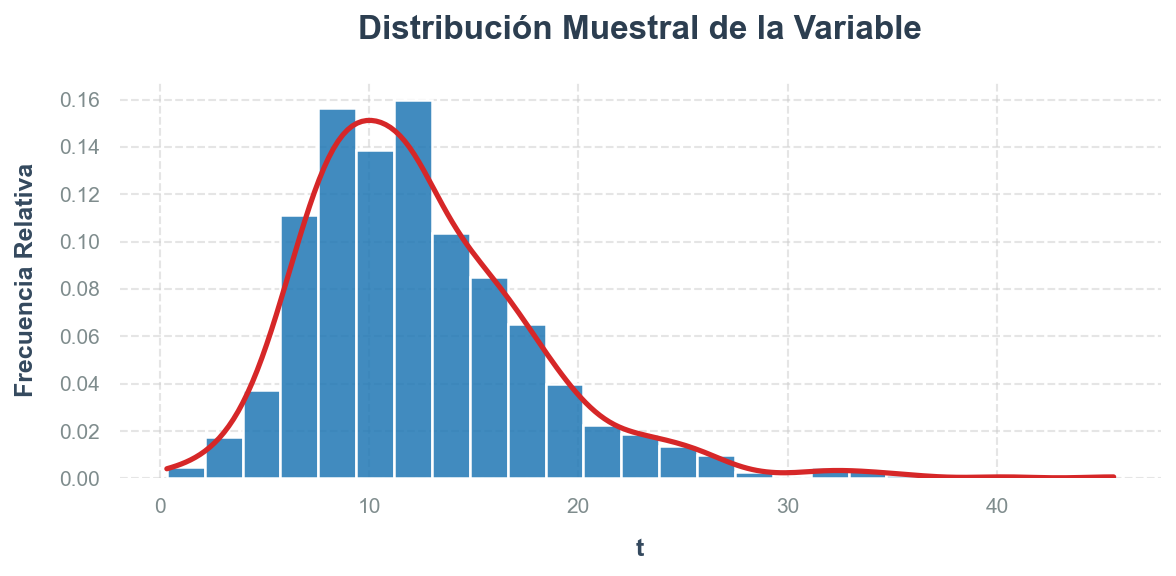

In [111]:
path_4 = "C:/Users/Skull/Escritorio/OneDrive/Universidad/Modelos Lineales I/Guía 1/Quarto/valoresExtremos.csv"
#path_4 = "C:/Users/emili/Desktop/OneDrive/Universidad/Modelos Lineales I/Guía 1/Quarto/valoresExtremos.csv"
df_4 = pd.read_csv(path_4)

sns.set_theme(style="whitegrid", rc={"grid.linestyle": "--", "grid.alpha": 0.5})
color_ejecutivo = "#1f77b4" 
fig, ax = plt.subplots(figsize=(8, 4), dpi=150)
sns.histplot(
    data=df_4,
    x="t",  
    bins=25,
    kde=True,   
    stat="probability",              
    color=color_ejecutivo,
    edgecolor="white",        
    linewidth=1.2,
    alpha=0.85,              
    ax=ax
)

if ax.lines:
    ax.lines[0].set_color("#d62728")  
    ax.lines[0].set_linewidth(2.5)

plt.title("Distribución Muestral de la Variable", fontsize=16, fontweight="bold", pad=20, color="#2c3e50")
plt.xlabel("t", fontsize=12, fontweight="semibold", labelpad=10, color="#34495e")
plt.ylabel("Frecuencia Relativa", fontsize=12, fontweight="semibold", labelpad=10, color="#34495e")

sns.despine(left=True, bottom=True)  
ax.tick_params(colors="#7f8c8d", labelsize=10) 

plt.tight_layout()
# plt.savefig("histograma_ejecutivo.png", bbox_inches='tight', transparent=True) #Por si se necesita guardar
plt.show()

Así podemos observar una distribución leptocúrtica, con sesgo positivo. Parece tener una media al rededor del 10, por lo que tal vez alguno de los parámetros este relacionado con este valor.
La función de supervivencia teórica:
$$S(t;\mu,\lambda)=1-exp\left(-exp\left(-\frac{t-\mu}{\lambda}\right)\right),$$
Linealización:
$$ln\left(-ln\left(1-S(t;\mu,\lambda)\right)\right) = \frac{\mu}{\lambda}-\frac{t}{\lambda} = \beta_0+\beta_1 t$$
Y por lo tanto, una vez que el modelo sea ajustado, los parámetros serán estimados por:
$$\mu=-\frac{\beta_0}{\beta_1}, \hspace{0.5cm} \lambda=-\frac{1}{\beta_1}$$
Donde al tener únicamente una muestra, estimamos la supervivencia de la siguiente manera:
$$\hat S_1(t)=\frac{(\text{cantidad de valores} > t) +\frac{1}{2}}{n}=\hat S_C(t)+\frac{1}{2n}$$
No es la función de supervivencia clásica (aunque esta relacionada), sumamos $1/(2n)$ debido que en la versión clásica habría un problema con el último dato ya que al hacer la transformación se tendría $ln(-ln(1-\frac{0}{n}))=ln(-ln(1))=ln(0)$ lo cual no esta definido, así aseguramos que este entre 0 y 1 sin eliminar observaciones.
Así aplicando el modelo propuesto, los coeficientes y $R^2$ son:

In [112]:
#Son los valores de t
aux_4 = df_4.iloc[:,0]
k_4 = len(aux_4)
#Calculamos la supervivencia
X_reg_4 = np.sort(aux_4)
Y_aux_4 = np.array([(np.sum(X_reg_4 > t) + 1/2) / k_4 for t in X_reg_4])
Y_reg_4 = np.log(-np.log(1-Y_aux_4)) #Supervivencia linealizada

#Ajustamos la regresión
X_reg_4 = sm.add_constant(X_reg_4)
reg_mod_4 = sm.OLS(Y_reg_4, X_reg_4).fit()



In [113]:
tabla_reg_4 = pd.DataFrame({'Estadístico': ['R2', 'beta_0', 'beta_1'],
    'Valor': [
        reg_mod_4.rsquared,
        reg_mod_4.params[0],
        reg_mod_4.params[1]
    ],
    'p-value (t)': [
        '-',
        reg_mod_4.pvalues[0],
        reg_mod_4.pvalues[1]
    ]})

tabla_reg_4.style.hide(axis="index")

Estadístico,Valor,p-value (t)
R2,0.996548,-
beta_0,2.272481,0.000000
beta_1,-0.229699,0.000000


Tenemos un $R^2$ muy alto el 99.65% de la variabilidad es explicada por los datos de la muestra, en parte así lo construimos a través de la linealización, los coeficientes son significativos, con el valor de estos últimos nos quedan las siguientes estimaciones de $\mu$ y $\lambda$

In [114]:
b0_4 = reg_mod_4.params[0]
b1_4 = reg_mod_4.params[1]
mu_4 = -(b0_4/b1_4)
lambda_4 = -(1/b1_4)
tabla_params_4 = pd.DataFrame({'Parámetro': ['mu', 'lambda'], 'Valor': [mu_4, lambda_4]})
tabla_params_4.style.hide(axis="index")

Parámetro,Valor
mu,9.893283
lambda,4.353516


Obtenidos estos parámetros es posible calcular la función de supervivencia teórica y compararla con la empírica clásica (a la empírica $S_1(t)$ le restaremos $1/(2n)$).

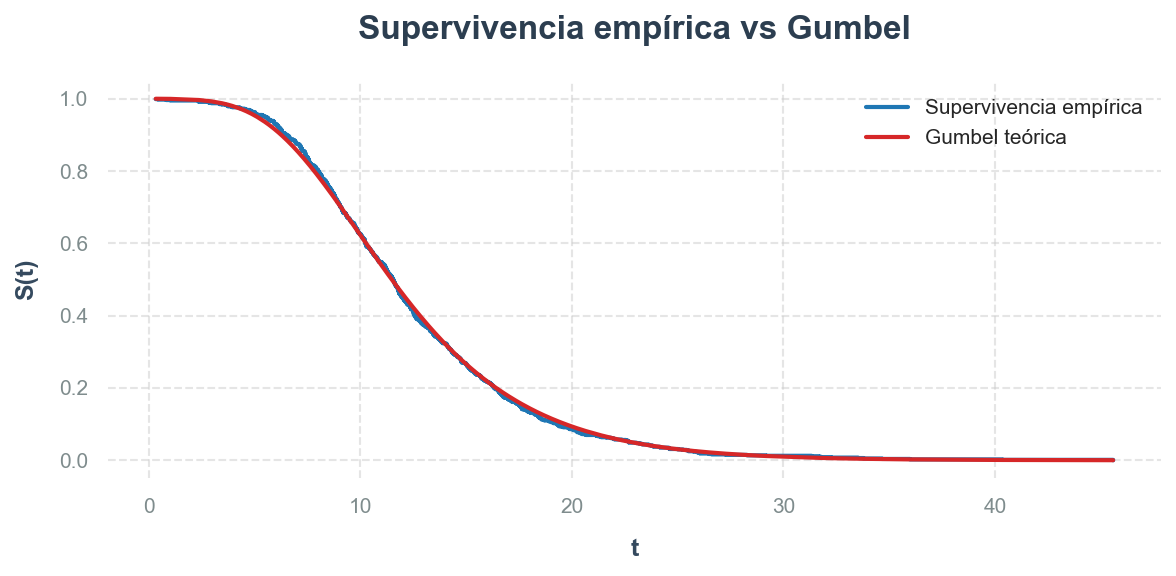

In [115]:
# Valores ordenados
t_4 = np.sort(aux_4)
n_4 = len(t_4)
#La dupervivencia empírica este en Y_aux_4 y la teórica:
S_gumbel_4 = 1 - np.exp(-np.exp(-(t_4 - mu_4) / lambda_4))
correc_4 = 1/(2*k_4) #Esta es la correción que hicimos a la empírica 

#Graficamos
sns.set_theme(style="whitegrid",rc={"grid.linestyle": "--", "grid.alpha": 0.5})
color_emp = "#1f77b4"
color_teorica = "#d62728"
fig, ax = plt.subplots(figsize=(8, 4), dpi=150)
# Supervivencia empírica
ax.step(
    t_4,
    Y_aux_4 - correc_4,
    where="post",
    color=color_emp,
    linewidth=2,
    label="Supervivencia empírica"
)

# Supervivencia teórica Gumbel
ax.plot(
    t_4,
    S_gumbel_4,
    color=color_teorica,
    linewidth=2,
    label="Gumbel teórica"
)

ax.set_title(
    "Supervivencia empírica vs Gumbel",
    fontsize=16,
    fontweight="bold",
    pad=20,
    color="#2c3e50"
)

ax.set_xlabel(
    "t",
    fontsize=12,
    fontweight="semibold",
    labelpad=10,
    color="#34495e"
)

ax.set_ylabel(
    "S(t)",
    fontsize=12,
    fontweight="semibold",
    labelpad=10,
    color="#34495e"
)

ax.legend(frameon=False, fontsize=10)

sns.despine(left=True, bottom=True)

ax.tick_params(
    colors="#7f8c8d",
    labelsize=10
)

plt.tight_layout()

plt.show()

Así el modelo propuesto, la estimación de los parámetros y la gráfica de comparación de funciones de supervivencia que presenta casi una superposición exacta, nos indica un buen ajuste, por lo que se podría utilizar la distribución con parámetros estimados para realizar conclusiones sobre el fenómeno estudiado.

## **Ejercicio 5**
Habíamos definido el vector de errores $e=Y-\hat Y$. Demuestre que los residuos son ortogonales al vector de predicciones, es decir: 
$$\hat Y'e=0$$
**Demostración.**
Recordemos que en el modelo lineal al resolverlo por mínimos cuadrados se llega a la siguiente ecuación normal:
$$X'X\hat\beta=X'Y$$
Que en este caso suponiendo que el modelo tiene solución se tiene que $X'X$ es invertible, así se llega a la solución de los coeficientes:
$$\hat\beta=(X'X)^{-1}X'Y$$
Los valores ajustados son $\hat Y= X\hat\beta$ y los residuos $e=Y-\hat Y$. Retomando la ecuación normal:
$$X'X\hat\beta=X'Y\Longrightarrow X'Y-X'X\hat\beta=0 \Longrightarrow X'(Y-X\hat\beta)=0 \Longrightarrow X'(Y-\hat Y)=0 \Longrightarrow X'e=o$$
Es decir los residuos son ortogonales a cada fila de $X'$, además recordando que $(AB)'=B'A'$ se llega a:
$$\hat Y'e=(X\hat\beta)'e=\hat\beta'X'e=0\hspace{0.2cm}\text{esto ya que}\hspace{0.2cm}X'e=0$$
$$\therefore \hat Y'e=0 \tag*{\rule{1ex}{1ex}}$$

## **Ejercicio 6**

Considerando el siguiente modelo de regresión lineal múltiple sin intercepto:
$$Y=\beta_1X_1+\beta_2X_2+\beta_3X_3$$
Donde la tercer variable es multicolineal de la siguiente manera: $X_3=2X_1+X_2$ demuestre que:

a) $X'X$ no es invertible

**Demostración. (Contradicción)**
Procedemos a través del Álgebra Lineal. Observando que el modelo puede escribirse de la forma $Y=X\beta+\varepsilon$ con $X=(X_1,X_2,X_3)$ vectores columna y se cumple que $X_3=2X_1+X_2\Longrightarrow 2X_1+X_2-X_3=0$, es decir, una combinación lineal de las columnas, esto implica que existe un vector no nulo $\vec{c}$ tal que $X\vec{c}=0$. Este vector es:
$$\vec{c}= \begin{pmatrix} 2 \\ 1 \\ -1 \end{pmatrix} \neq \vec{0} \Longrightarrow X\vec{c}=(X_1,X_2,X_3)\begin{pmatrix} 2 \\ 1 \\ -1 \end{pmatrix}=2X_1+X_2-X_3=\vec{0}$$
Esto implica que $Ker(X)\neq\{\vec{0}\}$ y por lo tanto $X$ no tiene rango columna completo.
Ahora supongamos por contradicción que $X'X$ es invertible, entonces $Ker(X'X)=\{\vec{0}\}$, pero considerando el vector $\vec{c}\neq\vec{0}$ anterior:
$$(X'X)\vec{c}=X'(X\vec{c})=X'(\vec{0})=\vec{0} \hspace{0.3cm}\text{ya que}\hspace{0.3cm}X'\vec{c}=\vec{0}$$
Entonces $\vec{c}\in Ker(X'X)$ lo cual es una contradicción de suponer que $Ker(X'X)=\{\vec{0}\}$, por lo tanto debe ser que $Ker(X'X)\neq\{\vec{0}\}$
$$\therefore X'X\hspace{0.2cm}\text{no es invertible}\tag*{\rule{1ex}{1ex}}$$

b) $X'X$ tiene un valor propio igual a 0.

**Demostración.**
Utilizando el vector $\vec{c}$ de la demostración anterior y que $(X'X)\vec{c}=0$, además recordando que $\lambda$ es un valor propio de una matriz $A$ si existe un vector no nulo $\vec{v}$ tal que $A\vec{v}=\lambda \vec{v}$, se tiene:
$$\vec{c}= \begin{pmatrix} 2 \\ 1 \\ -1 \end{pmatrix} \neq \vec{0}\Longrightarrow (X'X)\vec{c}=\vec{0}=0\vec{c}$$
$$\therefore \lambda=0\hspace{0.2cm} \text{es un valor propio de } X'X \tag*{\rule{1ex}{1ex}}$$





## **Ejercicio 7**

El comportamiento de los datos dentro del conjunto de datos dataset1.csv inmediatamente destaca una relación polinómica, al tener 2 puntos de inflexión parece demasiado a la gráfica de un polinomio de grado 3, es decir $f(x)=a+bx+cx^2+dx^3$, por ello es el modelo propuesto para describir la tendencia de la nube de puntos es:
$$Y=\beta_0+\beta_1X+\beta_2X^2+\beta_3X^3$$
En el cuál se obtuvieron los siguientes coeficientes y significancia.

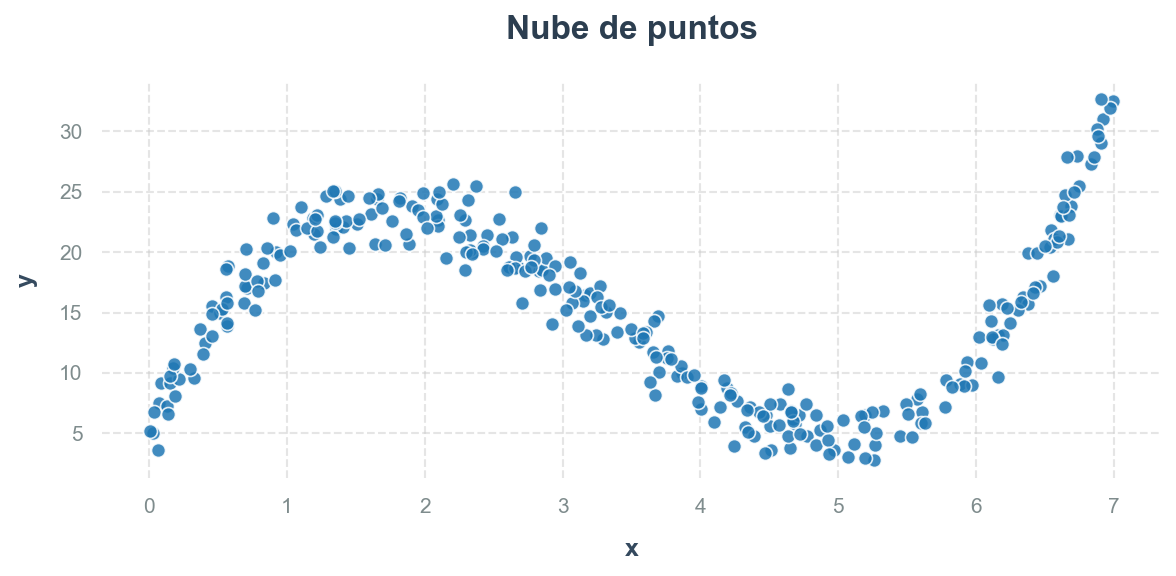

In [116]:
#| output: false
#Veamos la nube de puntos aunque no lo mostramos en el documento final
path_7 = "C:/Users/Skull/Escritorio/OneDrive/Universidad/Modelos Lineales I/Guía 1/Quarto/dataset1.csv"
df_7 = pd.read_csv(path_7)
x_7 = df_7["x"]
X_poli_7 = np.column_stack((x_7, x_7**2, x_7**3))
Y_reg_7 = df_7["y"]

sns.set_theme(
    style="whitegrid",
    rc={"grid.linestyle": "--", "grid.alpha": 0.5}
)

color_ejecutivo = "#1f77b4"

fig, ax = plt.subplots(figsize=(8, 4), dpi=150)

sns.scatterplot(
    x=x_7,
    y=Y_reg_7,
    color=color_ejecutivo,
    s=45,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.8,
    ax=ax
)

ax.set_title(
    "Nube de puntos",
    fontsize=16,
    fontweight="bold",
    pad=20,
    color="#2c3e50"
)

ax.set_xlabel(
    "x",
    fontsize=12,
    fontweight="semibold",
    labelpad=10,
    color="#34495e"
)

ax.set_ylabel(
    "y",
    fontsize=12,
    fontweight="semibold",
    labelpad=10,
    color="#34495e"
)

sns.despine(left=True, bottom=True)

ax.tick_params(
    colors="#7f8c8d",
    labelsize=10
)

plt.tight_layout()

# plt.savefig(
#     "nube_puntos_7.png",
#     bbox_inches="tight",
#     transparent=True
# )

plt.show()

In [117]:
X_reg_7 = sm.add_constant(X_poli_7)
reg_mod_7 = sm.OLS(Y_reg_7,X_reg_7).fit()

tabla_coef_7 = pd.DataFrame({"Variable": reg_mod_7.params.index,
    "Coeficiente": reg_mod_7.params.values,
    "Error estándar": reg_mod_7.bse.values,
    "t": reg_mod_7.tvalues.values,
    "p-valor": reg_mod_7.pvalues.values,
    "[0.025": reg_mod_7.conf_int()[0].values,
    "0.975]": reg_mod_7.conf_int()[1].values})


tabla_coef_7.style.format({"Coeficiente": "{:.4f}",
        "Error estándar": "{:.4f}",
        "t": "{:.4f}",
        "p-valor": "{:.2e}",
        "[0.025": "{:.4f}",
        "0.975]": "{:.4f}"}).hide(axis="index")


Variable,Coeficiente,Error estándar,t,p-valor,[0.025,0.975]
const,4.5594,0.3408,13.3798,2.97e-32,3.8887,5.2300
x1,25.4713,0.4291,59.3610,1.97e-166,24.6268,26.3157
x2,-10.1413,0.1449,-69.9828,3.47e-186,-10.4265,-9.8561
x3,1.0124,0.0137,74.0248,5.14e-193,0.9855,1.0393


Donde podemos observar que tenemos errores estándar pequeños en comparación a los coeficientes, los p-value de todos los coeficientes son muy pequeños, lo que implica que en su forma individual son significativos a un nivel de significancia del 0.05. Veamos que el modelo es significativo a través de la tabla ANOVA.

In [118]:
# Grados de libertad
gl_reg_7 = int(reg_mod_7.df_model)
gl_error_7 = int(reg_mod_7.df_resid)
gl_total_7 = gl_reg_7 + gl_error_7

# Sumas de cuadrados
SC_reg_7 = reg_mod_7.ess
SC_error_7 = reg_mod_7.ssr
SC_total_7 = SC_reg_7 + SC_error_7

# Cuadrados medios
CM_reg_7 = SC_reg_7 / gl_reg_7
CM_error_7 = SC_error_7 / gl_error_7

# Estadístico F y p-valor
F_7 = reg_mod_7.fvalue
p_valor_7 = reg_mod_7.f_pvalue

tabla_anova_7 = pd.DataFrame({
    "Fuente": ["Regresión", "Error", "Total"],
    "gl": [gl_reg_7, gl_error_7, gl_total_7],
    "SC": [SC_reg_7, SC_error_7, SC_total_7],
    "CM": [CM_reg_7, CM_error_7, None],
    "F": [F_7, None, None],
    "p-valor": [p_valor_7, None, None]
})


tabla_anova_7.style.format({
        "SC": "{:.4f}",
        "CM": "{:.4f}",
        "F": "{:.4f}",
        "p-valor": "{:.3e}"}).hide(axis="index")

Fuente,gl,SC,CM,F,p-valor
Regresión,3,14437.5496,4812.5165,1994.1063,6.290e-196
Error,296,714.3576,2.4134,nan,nan
Total,299,15151.9072,nan,nan,nan


Cuyo p-value es menor a 0.05, por lo que el modelo es estadísticamente significativo, al menos una de las potencias de la variable x esta aportando información relevante al modelo. Adicionalmente se tiene un coeficiente de determinación $R^2=0.952853$, es decir el 95.28% de la variabilidad en Y es explicada por los predictores involucrados. Así considerando los coeficientes, el modelo ajustado y gráfica de ajuste son:
$$Y=4.5594+25.4713X-10.1413X^2+1.0124X^3$$

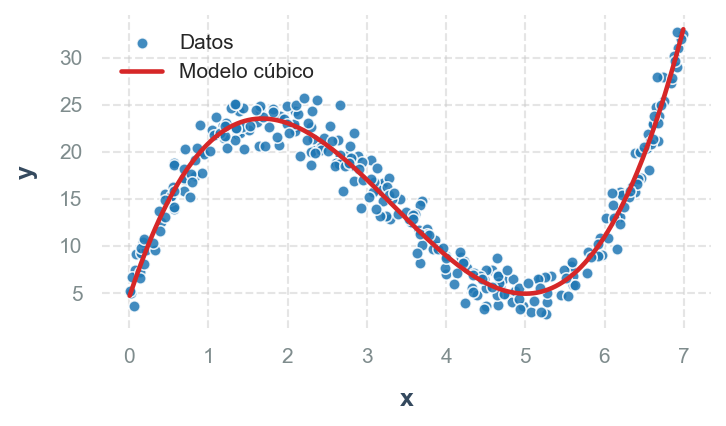

In [119]:
#| fig-align: center
x_linea_7 = np.linspace(x_7.min(), x_7.max(), 300) #Valores para gráficar x
X_linea_7 = np.column_stack((x_linea_7,x_linea_7**2,x_linea_7**3)) #Valores x. x^2, x^3
X_linea_7 = sm.add_constant(X_linea_7) #Añadimos la constante
y_linea_7 = reg_mod_7.predict(X_linea_7) #Predecimos con el modelo
# Gráfica
sns.set_theme(
    style="whitegrid",
    rc={"grid.linestyle": "--", "grid.alpha": 0.5}
)

color_estimado = "#1f77b4"
color_modelo = "#d62728"

fig, ax = plt.subplots(figsize=(5, 3), dpi=150)

# Nube de puntos
sns.scatterplot(
    x=x_7,
    y=Y_reg_7,
    color=color_estimado,
    s=30,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.8,
    ax=ax,
    label="Datos"
)

# Modelo cúbico
ax.plot(
    x_linea_7,
    y_linea_7,
    color=color_modelo,
    linewidth=2.2,
    label="Modelo cúbico"
)
ax.set_xlabel(
    "x",
    fontsize=12,
    fontweight="semibold",
    labelpad=10,
    color="#34495e"
)

ax.set_ylabel(
    "y",
    fontsize=12,
    fontweight="semibold",
    labelpad=10,
    color="#34495e"
)

ax.legend(
    frameon=False,
    fontsize=10
)

sns.despine(left=True, bottom=True)

ax.tick_params(
    colors="#7f8c8d",
    labelsize=10
)

plt.tight_layout()

# plt.savefig(
#     "nube_puntos_modelo_7.png",
#     bbox_inches="tight",
#     transparent=True
# )

plt.show()

## **Ejercicio 8**

Con los datos dados en el ejercicio hagamos la comparación entre los dos modelos presentados a continuación. Considerando las siguientes variables: 

- Y: Precio estimado en Miles de dólares.
- X_1: Área construida (en $m^2$).
- X_2: Habitaciones.
- X_3: Garaje (1 si tiene 0 si no).

Modelo 1: $Y=\beta_0+\beta_1X_1+\beta_2X_2\\$
Modelo 2: $Y=\beta_0+\beta_1X_1+\beta_2X_2+\beta_3X_3$

Para el primer modelo se obtiene un $R^2 = 0.945$ y un $R^2_{ajust}=0.942$, mientras que para el segundo se obtiene un $R^2 = 0.976$ t y un $R^2_{ajust}=0.974$, es decir el segundo modelo presenta una mejor explicación de la variabilidad de la variable objetivo, ambos modelos tienen coeficientes significativos en conjunto con valores $F$ asociados a la tabla ANOVA de $303.1$ y $454.7$ respectivamente. Además, el modelo que no considera la variable Garaje obtuvo un error típico de $35.7745$ mientras que el que si la considera tuvo un error típico de $24.2272$. Los coeficientes y valores de significancia del primer modelo son:

In [120]:
path_8 = "C:/Users/Skull/Escritorio/OneDrive/Universidad/Modelos Lineales I/Guía 1/Quarto/Ej_8.csv"
df_8 = pd.read_csv(path_8)
xsg_8 = df_8[["Area(m2)", "Habitaciones"]]
xcg_8 = df_8[["Area(m2)", "Habitaciones", "Garaje(dummy)"]]
X_reg_sg_8 = sm.add_constant(xsg_8)
X_reg_cg_8 = sm.add_constant(xcg_8)
Y_reg_8 = df_8["Precio estimado en Mil dólares"]

reg_mod_sg_8 = sm.OLS(Y_reg_8, X_reg_sg_8).fit()
reg_mod_cg_8 = sm.OLS(Y_reg_8, X_reg_cg_8).fit()

In [121]:
#| output: false
print(reg_mod_sg_8.summary()) #Tiene alto valor de condición (974) pero sabemos que python no lo calcula normalizando las columnas. 
print(np.sqrt(reg_mod_sg_8.scale)) #Error típico de la regresión
num_cond_3(reg_mod_sg_8) #Número de condición ya normalizado 28.9287 multicolinealidad moderada
X_sg_8 = reg_mod_sg_8.model.exog
nombres_Xsg_8 = reg_mod_sg_8.model.exog_names
vifsg_8 = pd.DataFrame({"Variable": nombres_Xsg_8,
    "VIF": [
        variance_inflation_factor(X_sg_8, i)
        for i in range(X_sg_8.shape[1])]})
vifsg_8 #Hay presencia de multicolinealidad en las variables Area, Habitaciones y el término constante. 

                                  OLS Regression Results                                  
Dep. Variable:     Precio estimado en Mil dólares   R-squared:                       0.945
Model:                                        OLS   Adj. R-squared:                  0.942
Method:                             Least Squares   F-statistic:                     303.1
Date:                            Sat, 26 Sep 2026   Prob (F-statistic):           7.92e-23
Time:                                    21:26:35   Log-Likelihood:                -188.29
No. Observations:                              38   AIC:                             382.6
Df Residuals:                                  35   BIC:                             387.5
Df Model:                                       2                                         
Covariance Type:                        nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
---------

,Variable,VIF
0,const,8.938423
1,Area(m2),17.654273
2,Habitaciones,17.654273


In [122]:
#| output: false
print(reg_mod_cg_8.summary()) #Incrementa el número de condición, aunque es engañoso por no normalizar la matriz diseño.
print(np.sqrt(reg_mod_cg_8.scale))
num_cond_3(reg_mod_cg_8) #Número de condición ya normalizado 32.5593 multicolinealidad severa, tiene sentido al ingresar una variable más
X_cg_8 = reg_mod_cg_8.model.exog
nombres_Xcg_8 = reg_mod_cg_8.model.exog_names
vifcg_8 = pd.DataFrame({"Variable": nombres_Xcg_8,
    "VIF": [
        variance_inflation_factor(X_cg_8, i)
        for i in range(X_cg_8.shape[1])]})
vifcg_8 #Hay presencia de multicolinealidad en las variables Area, Habitaciones y el término constante, la dummy no esta involucrada.

                                  OLS Regression Results                                  
Dep. Variable:     Precio estimado en Mil dólares   R-squared:                       0.976
Model:                                        OLS   Adj. R-squared:                  0.974
Method:                             Least Squares   F-statistic:                     454.7
Date:                            Sat, 26 Sep 2026   Prob (F-statistic):           1.71e-27
Time:                                    21:26:35   Log-Likelihood:                -172.93
No. Observations:                              38   AIC:                             353.9
Df Residuals:                                  34   BIC:                             360.4
Df Model:                                       3                                         
Covariance Type:                        nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
--------

,Variable,VIF
0,const,10.896199
1,Area(m2),18.846303
2,Habitaciones,18.714359
3,Garaje(dummy),1.068471


In [123]:
tabla_coef_sg_8 = pd.DataFrame({"Variable": reg_mod_sg_8.params.index,
    "Coeficiente": reg_mod_sg_8.params.values,
    "Error estándar": reg_mod_sg_8.bse.values,
    "t": reg_mod_sg_8.tvalues.values,
    "p-valor": reg_mod_sg_8.pvalues.values,
    "[0.025": reg_mod_sg_8.conf_int()[0].values,
    "0.975]": reg_mod_sg_8.conf_int()[1].values})


tabla_coef_sg_8.style.format({"Coeficiente": "{:.4f}",
        "Error estándar": "{:.4f}",
        "t": "{:.4f}",
        "p-valor": "{:.4f}",
        "[0.025": "{:.4f}",
        "0.975]": "{:.4f}"}).hide(axis="index")

Variable,Coeficiente,Error estándar,t,p-valor,[0.025,0.975]
const,11.8888,17.3505,0.6852,0.4977,-23.3347,47.1122
Area(m2),0.7194,0.2224,3.2351,0.0027,0.2679,1.1708
Habitaciones,24.5625,9.2104,2.6668,0.0115,5.8644,43.2606


Observemos que los coeficientes relacionados a las variables explicativas de este modelo son significativos, mientras que el de el intercepto no, su error estándar es grande tal vez se deba a presencia de multicolinealidad no esencial, algo similar ocurrido en el modelo profundizado del ejercicio 3. Para el modelo que si considera si la casa tiene o no garaje:

In [124]:
tabla_coef_cg_8 = pd.DataFrame({"Variable": reg_mod_cg_8.params.index,
    "Coeficiente": reg_mod_cg_8.params.values,
    "Error estándar": reg_mod_cg_8.bse.values,
    "t": reg_mod_cg_8.tvalues.values,
    "p-valor": reg_mod_cg_8.pvalues.values,
    "[0.025": reg_mod_cg_8.conf_int()[0].values,
    "0.975]": reg_mod_cg_8.conf_int()[1].values})


tabla_coef_cg_8.style.format({"Coeficiente": "{:.4f}",
        "Error estándar": "{:.4f}",
        "t": "{:.4f}",
        "p-valor": "{:.4f}",
        "[0.025": "{:.4f}",
        "0.975]": "{:.4f}"}).hide(axis="index")

Variable,Coeficiente,Error estándar,t,p-valor,[0.025,0.975]
const,-23.8828,12.9733,-1.8409,0.0744,-50.2477,2.4820
Area(m2),0.9739,0.1556,6.2594,0.0000,0.6577,1.2901
Habitaciones,14.6199,6.4220,2.2765,0.0292,1.5688,27.6710
Garaje(dummy),52.8529,8.1250,6.5050,0.0000,36.3409,69.3649


En este caso los coeficientes de las variables predictoras siguen siendo significativos, el error típico de los mismos bajo y el intercepto (relacionado a la categoría de referencia: no tiene garaje) sigue siendo no significativo al nivel 0.05 pero su error estándar se redujo, una estadística adicional obtenida de ambos modelos es el BIC (castiga más a modelos más complejos), donde el primer modelo obtuvo 387.5 y el segundo 360.4. Así podemos concluir que el segundo modelo que incorpora la variable garaje es un modelo más completo, incrementando el $R^2$ y el $R^2_{ajust}$, disminuyendo el error típico de la regresión y de los coeficientes y resultando en un menor BIC.